# FCC-ee single-beam power loss

Supply a longitudinal impedance, choose an FCC-ee operation mode, and calculate single-beam power loss. The supplied IR central-pipe file is an example; every later cell uses the `bihc.Impedance` object `Z`, so you can use another measured or modeled impedance.

Use a Python kernel with this BIHC checkout installed (for example, `pip install -e .` from the repository root).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c

import bihc
from bihc.fillingschemes import (
    fillingSchemeFCCee_WW,
    fillingSchemeFCCee_ZH,
    fillingSchemeFCCee_ttbar,
)

## Load and inspect an impedance

This example loads the supplied 100 GHz central-pipe data. Replace the next cell with any public-API construction of a `bihc.Impedance` named `Z` to study another component. For this file, the first column is in GHz and there is one header line.

In [2]:
filename = "Z_long_bpm.txt"
path_to_file = "data/"

Z = bihc.Impedance()
Z.getImpedanceFromCST(path_to_file + filename, unit="GHz", skip_header=1)
print(f"Loaded {len(Z.f)} impedance points through {Z.f[-1] / 1e9:.0f} GHz")

Loaded 2104124 impedance points through 50 GHz


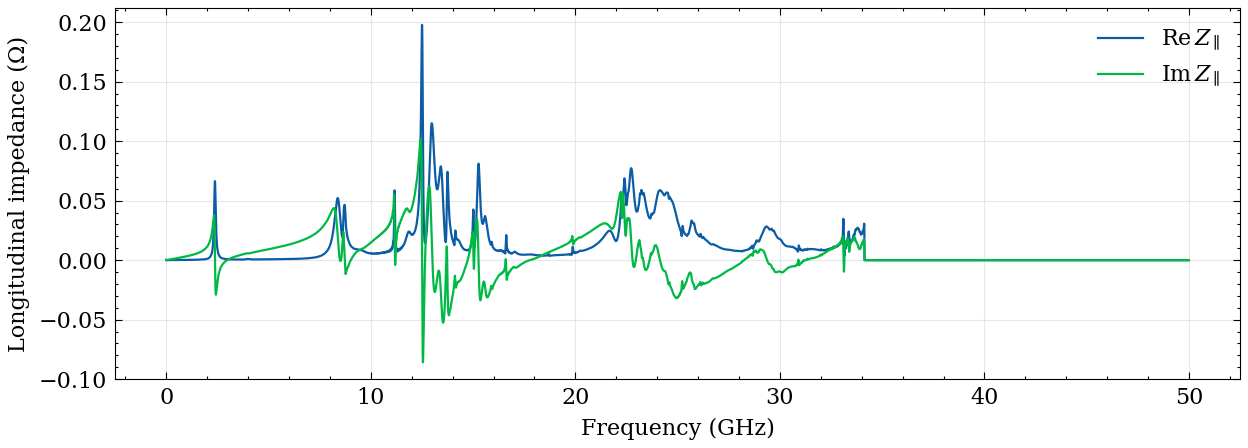

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(Z.f / 1e9, Z.Zr, label=r"$\mathrm{Re}\,Z_\parallel$")
ax.plot(Z.f / 1e9, Z.Zi, label=r"$\mathrm{Im}\,Z_\parallel$")
ax.set(xlabel="Frequency (GHz)", ylabel="Longitudinal impedance (Ω)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Choose an operation mode

A **train** and a **batch** mean the same bunch group. Several trains/batches form an injection. Filled bunches occupy adjacent slots within each train/batch; the numbers below are *empty* slots in each gap.

| Mode | Injections | Trains/batches per injection | Bunches per train/batch | Gap between trains/batches | Gap between injections |
| --- | ---: | ---: | ---: | ---: | ---: |
| ZH | 2 | 75 | 2 | 19 | 3,764 |
| WW | 8 | 58 | 4 | 16 | 371 |
| ttbar | 2 | 16 | 2 | 151 | 3,763 |

Each wrapper returns 12,120 occupied or empty slots. The nominal slot spacing is 25 ns; BIHC uses the FCC-ee revolution period to construct the beam.

In [4]:
mode = "ZH"  # Choose "ZH", "WW", or "ttbar".
modes = {
    "ZH": {
        "scheme": fillingSchemeFCCee_ZH,
        "sigma_z_mm": 5.59,
        "Np": 1.15e11,
        "ppbk": 1000,
    },
    "WW": {
        "scheme": fillingSchemeFCCee_WW,
        "sigma_z_mm": 5.40,
        "Np": 1.45e11,
        "ppbk": 1000,
    },
    "ttbar": {
        "scheme": fillingSchemeFCCee_ttbar,
        "sigma_z_mm": 2.33,
        "Np": 1.55e11,
        "ppbk": 2250,
    },
}
case = modes[mode]

## Build and inspect the beam

All three modes use a q-Gaussian bunch shape with $q=0.99$. BIHC expects `bunchLength` in seconds as $4\sigma_z/c$. The numeric spectrum uses a real FFT and keeps only nonnegative frequencies. With only `ppbk` specified, its Nyquist frequency sets the numeric range. An explicit `fmax` limits the returned spectrum and increases `ppbk` when needed to sample that range safely; BIHC warns when it increases `ppbk`. The sampling values below reproduce the supplied calculations; a warning means the bunch profile needs a `ppbk` convergence check before using the result quantitatively.

In [5]:
scheme = case["scheme"]()
beam = bihc.Beam(
    M=len(scheme),
    machine="FCC-ee",
    fillingScheme=scheme,
    Np=case["Np"],
    bunchLength=4 * case["sigma_z_mm"] * 1e-3 / c,
    bunchShape="q-GAUSSIAN",
    qvalue=0.99,
    ppbk=case["ppbk"],
    spectrum="numeric",
    verbose=False,
)
print(f"{mode}: {beam.filledSlots} bunches in {len(scheme)} slots")
print(f"Numeric spectrum reaches {beam.spectrum[0][-1] / 1e9:.1f} GHz")

Setting custom beam from filling scheme
Elaborating Data...
ZH: 300 bunches in 12120 slots
Numeric spectrum reaches 20.0 GHz


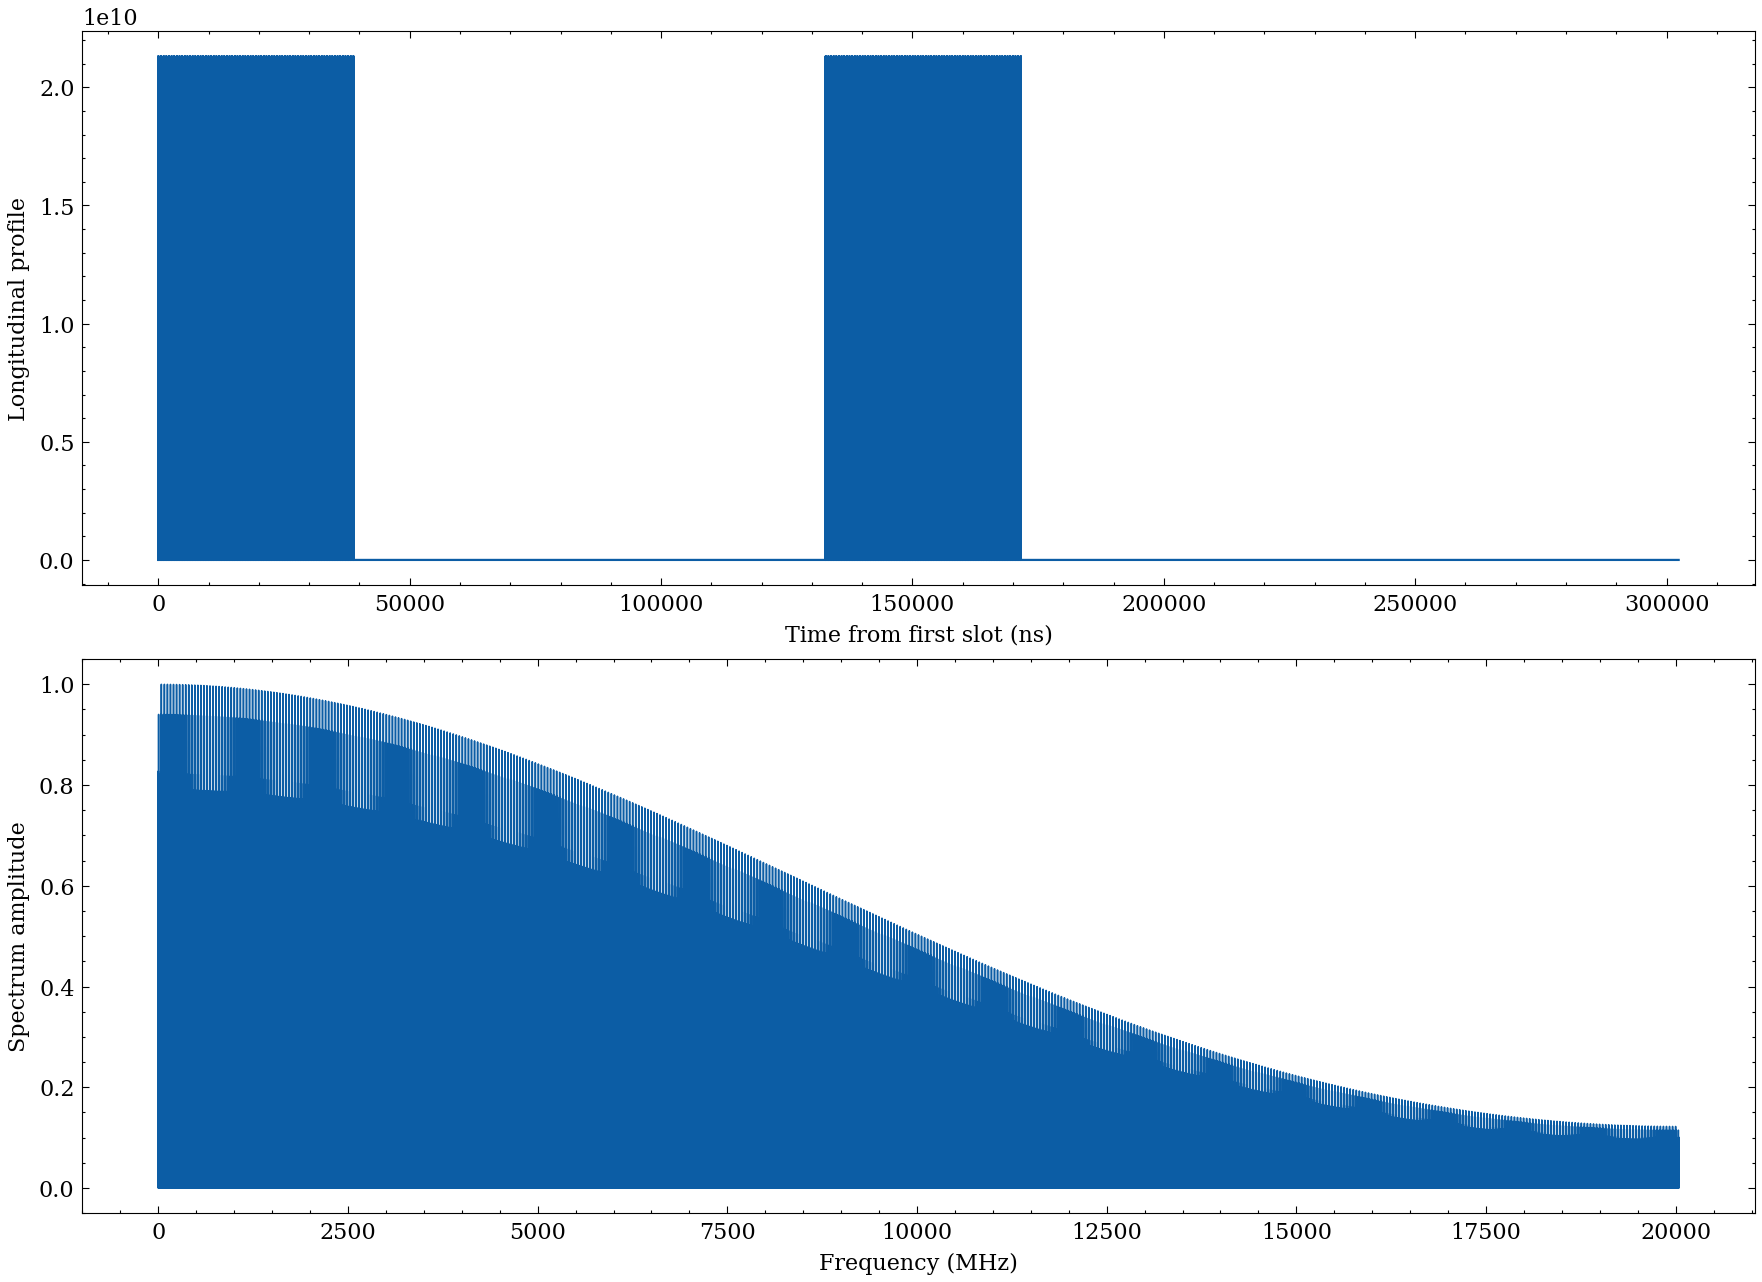

In [9]:
t, profile = beam.longitudinalProfile
f, amplitude = beam.spectrum

fig, axes = plt.subplots(2, 1, figsize=(11, 8), layout="constrained")

# Plot the longitudinal profile
axes[0].plot((t - t[0]) * 1e9, profile)
axes[0].set(
    xlabel="Time from first slot (ns)",
    ylabel="Longitudinal profile",
)

# Plot the computed beam spectrum
axes[1].plot(f[f > 0] / 1e6, amplitude[f > 0], lw=0.7)
axes[1].set(
    xlabel="Frequency (MHz)",
    ylabel="Spectrum amplitude",
)

plt.show()

## Single-beam power loss

In [ ]:
power_loss, power_density = beam.getPloss(Z)
print(f"{mode} single-beam power loss: {power_loss:.3f} W")

## Shifted power loss

Scan a rigid frequency shift of the **impedance** over half a bunch-spacing frequency on either side. The shift is not a change in beam arrival time. The scan uses the full numeric spectrum and needs more memory than the single loss calculation.

In [ ]:
steps, shifted_power = beam.getShiftedPloss(Z, shift=1 / (2 * beam.t0))
frequency_step = f[1] - f[0]
frequency_offset_mhz = steps * frequency_step / 1e6
print(f"Shifted range: {shifted_power.min():.3f}–{shifted_power.max():.3f} W")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(frequency_offset_mhz, shifted_power)
ax.set(xlabel="Impedance frequency offset (MHz)", ylabel="Power loss (W)")
ax.grid(alpha=0.3)
plt.show()

## Compare impedance and beam spectrum

Plot the impedance alongside the beam power spectrum to see where spectral content overlaps the impedance. The view is limited to 2 GHz or the available data range; individual revolution harmonics are more closely spaced than this plot can resolve.

In [ ]:
view_ghz = min(2, Z.f[-1] / 1e9, f[-1] / 1e9)
beam_range = (f >= 0) & (f <= view_ghz * 1e9)
impedance_range = Z.f <= view_ghz * 1e9

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(Z.f[impedance_range] / 1e9, Z.Zr[impedance_range], color="C0")
ax.set(
    xlabel="Frequency (GHz)",
    ylabel=r"$\mathrm{Re}\,Z_\parallel$ (Ω)",
    xlim=(0, view_ghz),
)
ax2 = ax.twinx()
ax2.plot(
    f[beam_range] / 1e9,
    beam.powerSpectrum[1][beam_range],
    color="C1",
    alpha=0.7,
    lw=0.7,
)
ax2.set_ylabel(r"Beam power spectrum $|S|^2$")
ax.grid(alpha=0.3)
plt.show()